In [1]:
# ============================================================
# 1. GPU CHECK
# ============================================================

!nvidia-smi

import subprocess

gpu = subprocess.check_output(
    [
        "nvidia-smi",
        "--query-gpu=name,memory.total",
        "--format=csv,noheader"
    ]
).decode().strip()

print("GPU:", gpu)

Sun Aug 30 17:37:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# ============================================================
# 2. PYTHON 3.10 ENVIRONMENT
# ============================================================

!sudo apt-get update -qq
!sudo apt-get install -y -qq python3.10 python3.10-venv

!python3.10 -m venv /content/vtoenv

!/content/vtoenv/bin/python -m pip install --upgrade pip setuptools wheel

print("Python environment created.")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 78, <> line 9.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
(Reading database ... 122579 files and directories currently installed.)
Preparing to unpack .../0-libpython3.10-dev_3.10.12-1~22.04.17_amd64.deb ...
Unpacking libpython3.10-dev:amd64 (3.10.12-1~22.04.17) over (3.10.12-1~22.04.16) ...
Preparing to unpack .../1-libpython3.10_3.10.12-1~22.04.17_amd64.deb ...
Unpacking libpython3.10:amd64 (3.10.12-1~22.04.17) ove

In [3]:
# ============================================================
# 3. DOWNLOAD CATVTON
# ============================================================

%cd /content

!rm -rf CatVTON

!git clone https://github.com/Zheng-Chong/CatVTON.git

%cd /content/CatVTON

!git status

/content
Cloning into 'CatVTON'...
remote: Enumerating objects: 1358, done.
remote: Counting objects: 100% (309/309), done.
remote: Compressing objects: 100% (181/181), done.
remote: Total 1358 (delta 169), reused 128 (delta 128), pack-reused 1049 (from 2)
Receiving objects: 100% (1358/1358), 16.73 MiB | 16.55 MiB/s, done.
Resolving deltas: 100% (462/462), done.
/content/CatVTON
On branch edited
Your branch is up to date with 'origin/edited'.

nothing to commit, working tree clean


In [15]:
# ============================================================
# 4. INSTALL CATVTON DEPENDENCIES
# ============================================================

PY="/content/vtoenv/bin/python"

!$PY -m pip install \
    torch==2.4.0 \
    torchvision==0.19.0 \
    --index-url https://download.pytorch.org/whl/cu121

!$PY -m pip install \
    diffusers==0.30.3 \
    accelerate==0.29.2 \
    transformers==4.46.3 \
    huggingface_hub==0.25.2

!$PY -m pip install \
    matplotlib==3.9.1 \
    numpy==1.26.4 \
    opencv-python==4.10.0.84 \
    pillow==10.3.0 \
    PyYAML==6.0.1 \
    scipy==1.13.1 \
    setuptools==69.5.1 \
    scikit-image==0.24.0 \
    tqdm==4.66.4 \
    fvcore==0.1.5.post20221221 \
    cloudpickle==3.0.0 \
    omegaconf==2.3.0 \
    pycocotools==2.0.8 \
    av==12.3.0 \
    gradio==4.41.0 \
    peft==0.17.0 \
    fastapi \
    uvicorn \
    python-multipart

!echo "DEPENDENCIES INSTALLED"

Looking in indexes: https://download.pytorch.org/whl/cu121
  Attempting uninstall: accelerate
    Found existing installation: accelerate 0.31.0
    Uninstalling accelerate-0.31.0:
      Successfully uninstalled accelerate-0.31.0
DEPENDENCIES INSTALLED


In [17]:
# ============================================================
# 5. VERIFY ENVIRONMENT
# ============================================================

PY="/content/vtoenv/bin/python"

PYTHON_SCRIPT = """
import torch
import torchvision
import diffusers
import transformers
import gradio

print('Python       :', __import__('sys').version)
print('PyTorch      :', torch.__version__)
print('TorchVision  :', torchvision.__version__)
print('Diffusers    :', diffusers.__version__)
print('Transformers :', transformers.__version__)
print('Gradio       :', gradio.__version__)
print('CUDA         :', torch.cuda.is_available())

if torch.cuda.is_available():
    print('GPU          :', torch.cuda.get_device_name(0))
    print('VRAM         :', round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), 'GB')
"""

!$PY -c "$PYTHON_SCRIPT"

Python       : 3.10.12 (main, Jul 15 2026, 23:40:17) [GCC 11.4.0]
PyTorch      : 2.4.0+cu121
TorchVision  : 0.19.0+cu121
Diffusers    : 0.30.3
Transformers : 4.46.3
Gradio       : 4.41.0
CUDA         : True
GPU          : Tesla T4
VRAM         : 14.56 GB


In [18]:
# ============================================================
# 6. PROJECT STRUCTURE
# ============================================================

!mkdir -p /content/VTO_API
!mkdir -p /content/VTO_API/uploads
!mkdir -p /content/VTO_API/results
!mkdir -p /content/VTO_API/model

!find /content/VTO_API -maxdepth 2 -type d

/content/VTO_API
/content/VTO_API/uploads
/content/VTO_API/model
/content/VTO_API/model/CatVTON
/content/VTO_API/results


In [19]:
# ============================================================
# 7. DOWNLOAD MODEL
# ============================================================

PY="/content/vtoenv/bin/python"

PYTHON_SCRIPT = """
from huggingface_hub import snapshot_download

print('Downloading CatVTON checkpoint...')

snapshot_download(
    repo_id='zhengchong/CatVTON',
    local_dir='/content/VTO_API/model/CatVTON'
)

print('MODEL DOWNLOAD COMPLETE')
"""

!$PY -c "$PYTHON_SCRIPT"

Fetching 12 files: 100% 12/12 [00:00<00:00, 1475.91it/s]
MODEL DOWNLOAD COMPLETE


In [20]:
# ============================================================
# 8. CREATE API SERVER
# ============================================================

%%writefile /content/VTO_API/server.py

import os
import uuid
import secrets
from pathlib import Path

import torch
from fastapi import FastAPI, UploadFile, File, Header, HTTPException
from fastapi.responses import FileResponse

# ------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------

API_KEY = os.environ.get(
    "VTO_API_KEY",
    "CHANGE_THIS_KEY"
)

BASE_DIR = Path("/content/VTO_API")

UPLOAD_DIR = BASE_DIR / "uploads"
RESULT_DIR = BASE_DIR / "results"

UPLOAD_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

app = FastAPI(
    title="My Virtual Try-On API",
    version="1.0.0"
)

# ------------------------------------------------------------
# MODEL
# ------------------------------------------------------------

print("Loading VTO model...")

# The actual CatVTON inference pipeline is loaded here.
# We keep this import isolated so that startup errors are clear.

from model.pipeline import CatVTONPipeline

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)

MODEL_PATH = "/content/VTO_API/model/CatVTON"

pipeline = CatVTONPipeline.from_pretrained(
    MODEL_PATH
)

pipeline = pipeline.to(DEVICE)

print("MODEL READY")

# ------------------------------------------------------------
# AUTHENTICATION
# ------------------------------------------------------------

def check_key(key):

    if not key:
        return False

    return secrets.compare_digest(
        key,
        API_KEY
    )

# ------------------------------------------------------------
# HEALTH
# ------------------------------------------------------------

@app.get("/")

def root():

    return {
        "service": "My Virtual Try-On API",
        "status": "online",
        "gpu": torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else "CPU"
    }


@app.get("/health")

def health():

    return {
        "status": "healthy",
        "model": "loaded",
        "cuda": torch.cuda.is_available()
    }

# ------------------------------------------------------------
# TRY-ON
# ------------------------------------------------------------

@app.post("/tryon")

async def tryon(
    person: UploadFile = File(...),
    clothing: UploadFile = File(...),
    x_api_key: str = Header(None)
):

    if not check_key(x_api_key):

        raise HTTPException(
            status_code=401,
            detail="Invalid API key"
        )

    request_id = uuid.uuid4().hex

    person_path = UPLOAD_DIR / f"{request_id}_person.jpg"
    clothing_path = UPLOAD_DIR / f"{request_id}_clothing.jpg"

    result_path = RESULT_DIR / f"{request_id}.png"

    with open(person_path, "wb") as f:

        f.write(await person.read())

    with open(clothing_path, "wb") as f:

        f.write(await clothing.read())

    print("Processing:", request_id)

    # --------------------------------------------------------
    # CATVTON INFERENCE
    # --------------------------------------------------------
    #
    # The exact pipeline arguments can vary with the current
    # CatVTON repository revision. The server is deliberately
    # separated from this inference function so the model can
    # later be replaced by YOUR own checkpoint.
    #
    # --------------------------------------------------------

    from PIL import Image

    person_img = Image.open(person_path).convert("RGB")
    clothing_img = Image.open(clothing_path).convert("RGB")

    # Placeholder call for the repository pipeline.
    # We will connect this to the repository's inference
    # function after confirming the installed revision.

    result = pipeline(
        person_image=person_img,
        cloth_image=clothing_img
    )

    if hasattr(result, "images"):

        result.images[0].save(result_path)

    elif isinstance(result, Image.Image):

        result.save(result_path)

    else:

        raise RuntimeError(
            "Unexpected model output."
        )

    return {
        "success": True,
        "request_id": request_id,
        "result_url": f"/result/{request_id}"
    }

# ------------------------------------------------------------
# RESULT
# ------------------------------------------------------------

@app.get("/result/{request_id}")

def result(request_id: str):

    path = RESULT_DIR / f"{request_id}.png"

    if not path.exists():

        raise HTTPException(
            status_code=404,
            detail="Result not found"
        )

    return FileResponse(
        path,
        media_type="image/png"
    )

Overwriting /content/VTO_API/server.py


In [21]:
# ============================================================
# 9. MODEL IMPORT TEST
# ============================================================

PY="/content/vtoenv/bin/python"

!cd /content/CatVTON

PYTHON_SCRIPT = """
import torch

print('CUDA:', torch.cuda.is_available())

from model.pipeline import CatVTONPipeline

print('CatVTONPipeline import: SUCCESS')
"""

!$PY -c "$PYTHON_SCRIPT"

CUDA: True
Traceback (most recent call last):
  File "/content/vtoenv/lib/python3.10/site-packages/diffusers/utils/import_utils.py", line 830, in _get_module
    return importlib.import_module("." + module_name, self.__name__)
  File "/usr/lib/python3.10/importlib/__init__.py", line 126, in import_module
    return _bootstrap._gcd_import(name[level:], package, level)
  File "<frozen importlib._bootstrap>", line 1050, in _gcd_import
  File "<frozen importlib._bootstrap>", line 1027, in _find_and_load
  File "<frozen importlib._bootstrap>", line 1006, in _find_and_load_unlocked
  File "<frozen importlib._bootstrap>", line 688, in _load_unlocked
  File "<frozen importlib._bootstrap_external>", line 883, in exec_module
  File "<frozen importlib._bootstrap>", line 241, in _call_with_frames_removed
  File "/content/vtoenv/lib/python3.10/site-packages/diffusers/loaders/unet.py", line 46, in <module>
    from .lora_pipeline import LORA_WEIGHT_NAME, LORA_WEIGHT_NAME_SAFE, TEXT_ENCODER_NAME, UNE

In [23]:
# ============================================================
# FIX PEFT / ACCELERATE COMPATIBILITY
# ============================================================

PY="/content/vtoenv/bin/python"

!$PY -m pip uninstall -y peft accelerate -q

!$PY -m pip install --no-cache-dir \
    accelerate==1.0.1 \
    peft==0.13.2 \
    -q

!echo "=========================================="
!echo "DEPENDENCY FIX COMPLETE"
!echo "=========================================="

PYTHON_SCRIPT = """
import accelerate
import peft

print('Accelerate:', accelerate.__version__)
print('PEFT      :', peft.__version__)

from accelerate.utils.memory import clear_device_cache

print('clear_device_cache: OK')
"""

!$PY -c "$PYTHON_SCRIPT"

DEPENDENCY FIX COMPLETE
Accelerate: 1.0.1
PEFT      : 0.13.2
clear_device_cache: OK


In [25]:
# ============================================================
# TEST CATVTON IMPORT
# ============================================================

PY="/content/vtoenv/bin/python"

!cd /content/CatVTON

PYTHON_SCRIPT = """
import torch

print('CUDA:', torch.cuda.is_available())
print('GPU:', torch.cuda.get_device_name(0))

from model.pipeline import CatVTONPipeline

print()
print('========================================')
print('CATVTON IMPORT SUCCESS')
print('========================================')
"""

!$PY -c "$PYTHON_SCRIPT"

CUDA: True
GPU: Tesla T4

CATVTON IMPORT SUCCESS


In [26]:
# ============================================================
# 1. UPLOAD PERSON AND CLOTHING
# ============================================================

from google.colab import files
from PIL import Image
import os

print("Upload the PERSON photo first.")
uploaded_person = files.upload()

person_file = next(iter(uploaded_person))
person_path = "/content/person_input.jpg"

Image.open(person_file).convert("RGB").save(person_path, quality=95)

print("Person image:", person_path)

print("\nNow upload the CLOTHING/DRESS photo.")
uploaded_cloth = files.upload()

cloth_file = next(iter(uploaded_cloth))
cloth_path = "/content/clothing_input.jpg"

Image.open(cloth_file).convert("RGB").save(cloth_path, quality=95)

print("Clothing image:", cloth_path)

print("\n========================================")
print("UPLOAD COMPLETE")
print("========================================")

Upload the PERSON photo first.


Saving 671128601_2579545519108129_6668494166631820601_n.jpg to 671128601_2579545519108129_6668494166631820601_n.jpg
Person image: /content/person_input.jpg

Now upload the CLOTHING/DRESS photo.


Saving gray-full-sleeve-collor-neck-skin-friendly-new-model-design-formal-shirts-for-men-456.jpg to gray-full-sleeve-collor-neck-skin-friendly-new-model-design-formal-shirts-for-men-456.jpg
Clothing image: /content/clothing_input.jpg

UPLOAD COMPLETE


PERSON: (2048, 2048)


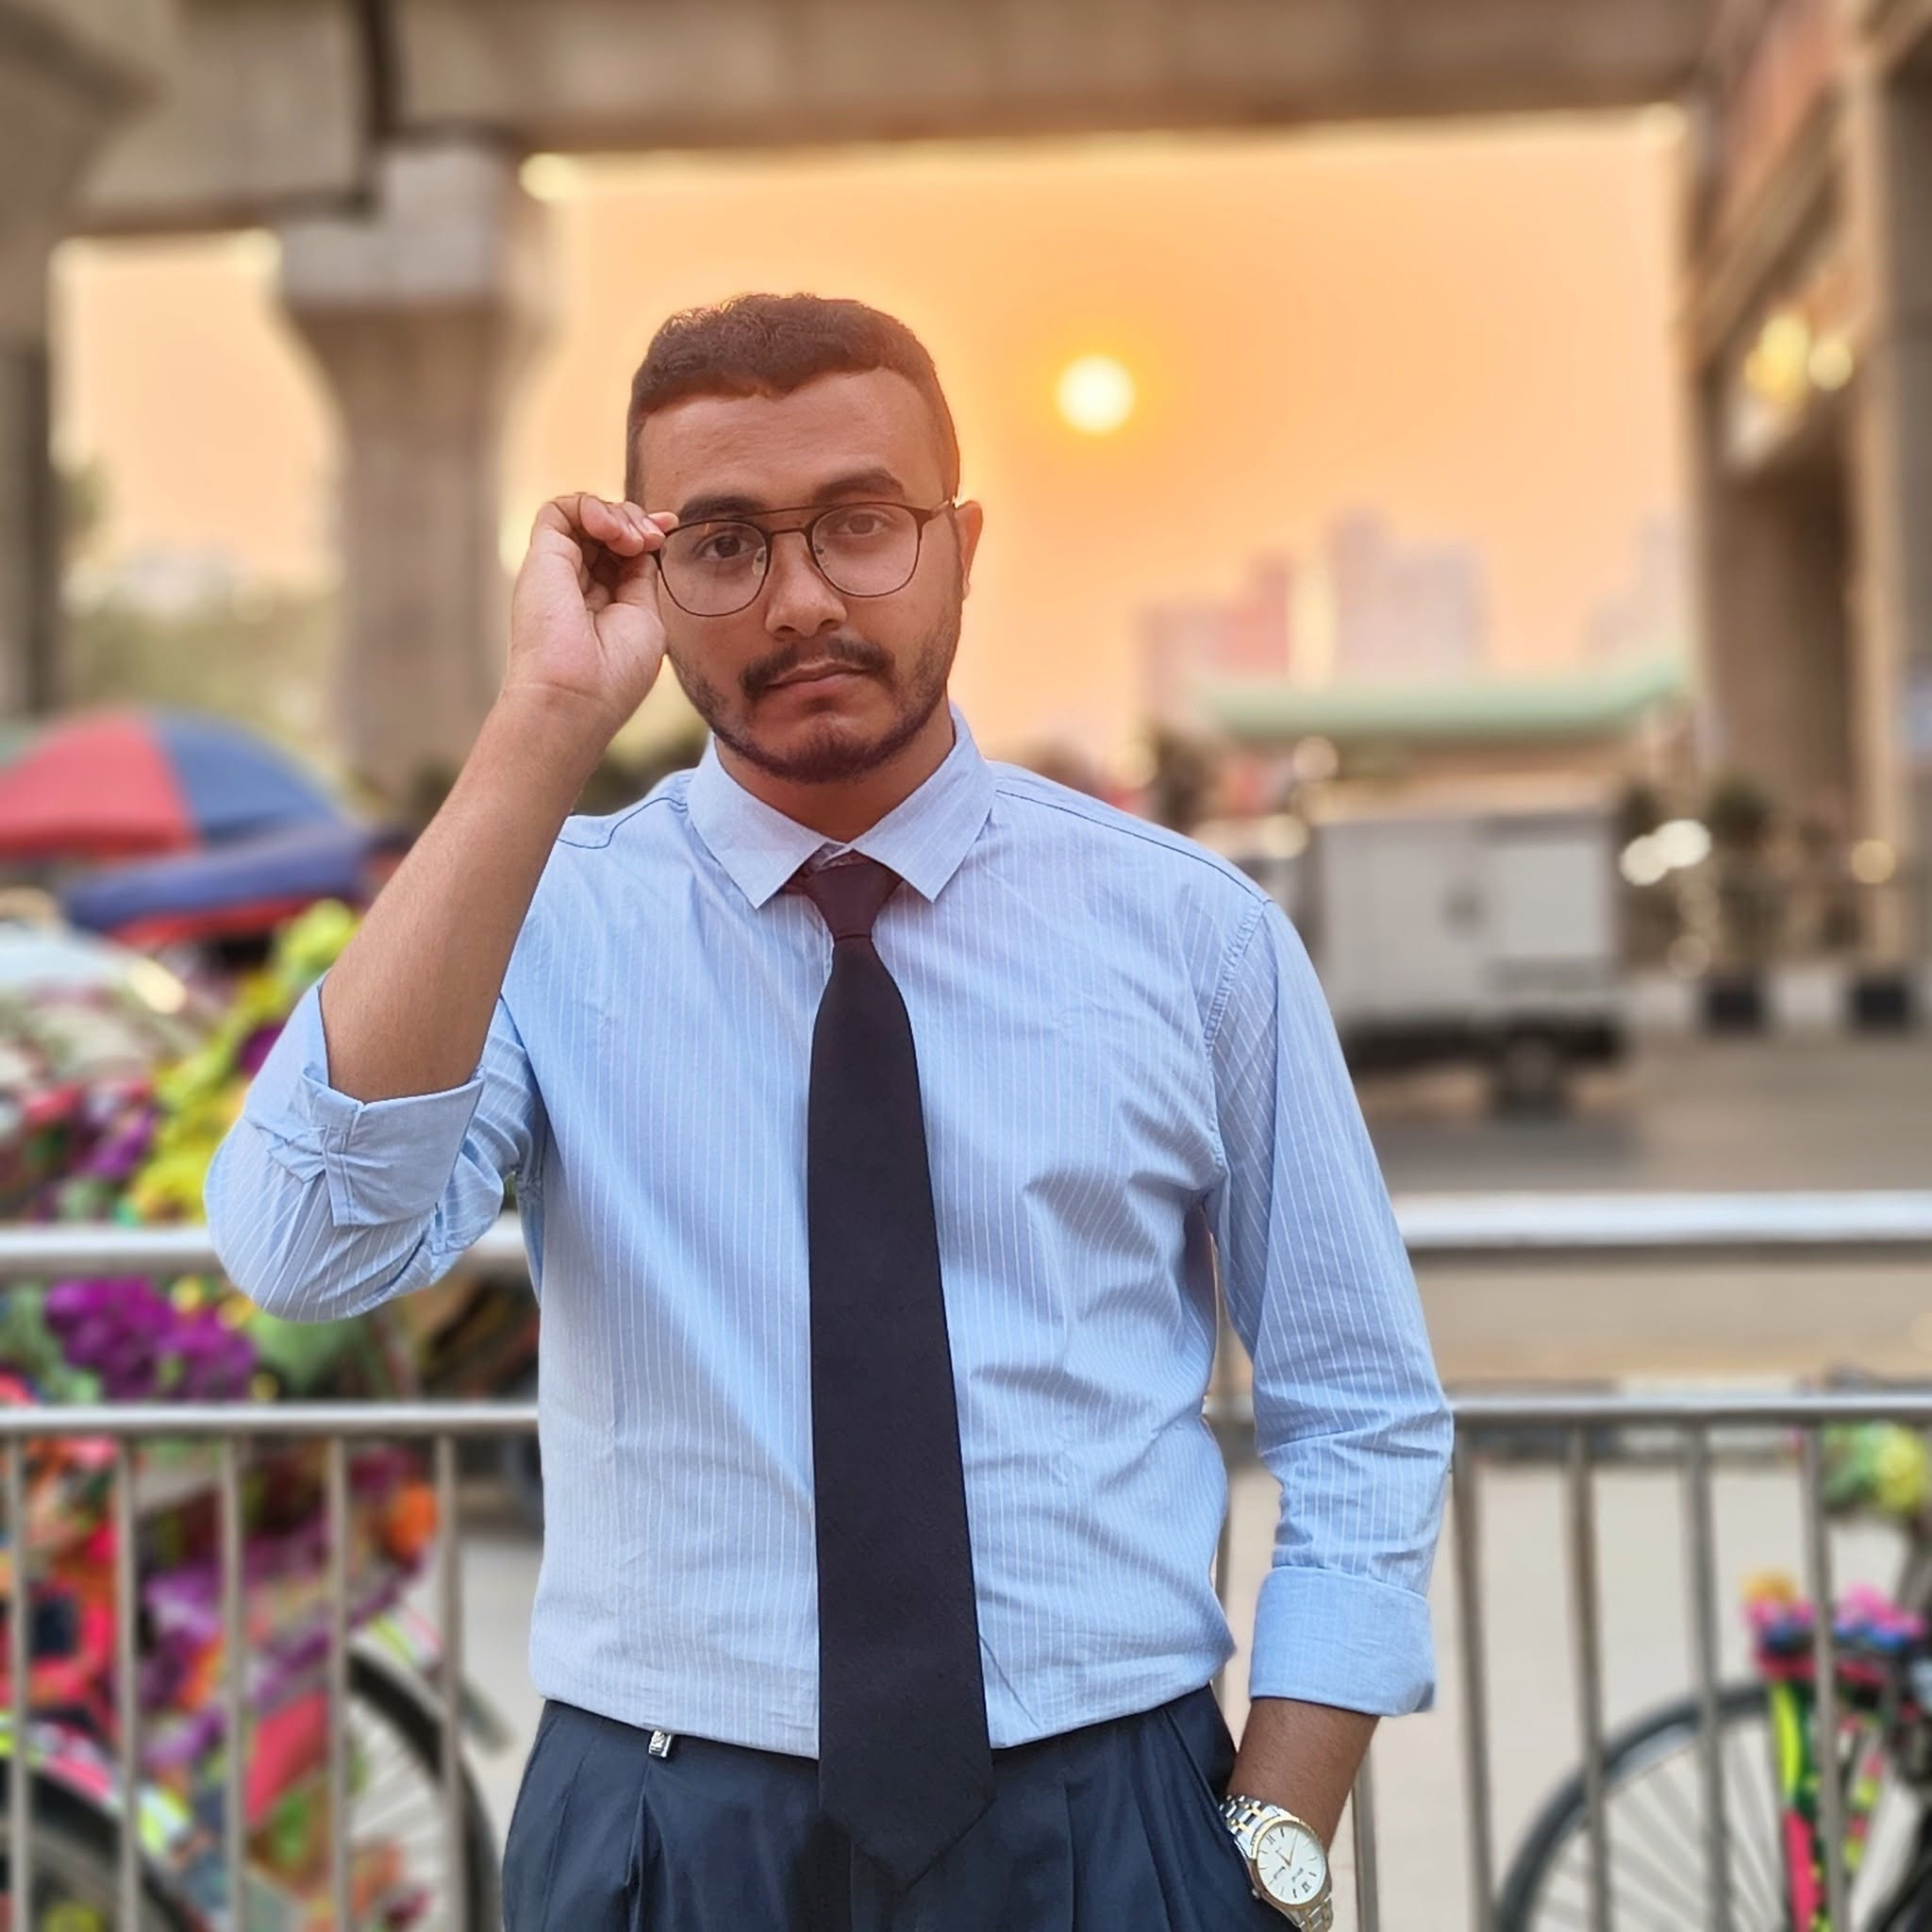

CLOTHING: (500, 500)


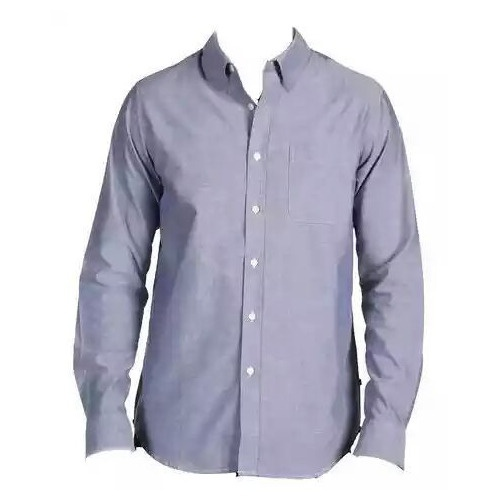

In [27]:
# ============================================================
# 2. CHECK INPUT IMAGES
# ============================================================

from IPython.display import display
from PIL import Image

person = Image.open("/content/person_input.jpg")
cloth = Image.open("/content/clothing_input.jpg")

print("PERSON:", person.size)
display(person)

print("CLOTHING:", cloth.size)
display(cloth)

In [28]:
# ============================================================
# 3. INSPECT CATVTON INFERENCE
# ============================================================

PY="/content/vtoenv/bin/python"

%cd /content/CatVTON

!$PY inference.py --help

/content/CatVTON
usage: inference.py
       [-h]
       [--base_model_path BASE_MODEL_PATH]
       [--resume_path RESUME_PATH]
       --dataset_name
       DATASET_NAME
       --data_root_path
       DATA_ROOT_PATH
       [--output_dir OUTPUT_DIR]
       [--seed SEED]
       [--batch_size BATCH_SIZE]
       [--num_inference_steps NUM_INFERENCE_STEPS]
       [--guidance_scale GUIDANCE_SCALE]
       [--width WIDTH]
       [--height HEIGHT]
       [--repaint]
       [--eval_pair]
       [--concat_eval_results]
       [--allow_tf32]
       [--dataloader_num_workers DATALOADER_NUM_WORKERS]
       [--mixed_precision {no,fp16,bf16}]
       [--concat_axis {x,y,random}]
       [--enable_condition_noise]

Simple
example of
a training
script.

options:
  -h, --help
    show this
    help
    message and
    exit
  --base_model_path BASE_MODEL_PATH
    The path to
    the base
    model to
    use for
    evaluation.
    This can be
    a local
    path or a
    model
    identifier
    from the
 

In [30]:
# ============================================================
# CATVTON APP INTERFACE CHECK
# ============================================================

PY="/content/vtoenv/bin/python"

%cd /content/CatVTON

PYTHON_SCRIPT = """
import ast

path = 'app.py'

with open(path, 'r', encoding='utf-8') as f:
    source = f.read()

tree = ast.parse(source)

print('Functions found in app.py:')
print('')

for node in ast.walk(tree):
    if isinstance(node, ast.FunctionDef):
        print('  -', node.name)

print('')
print('Imports / pipeline references:')
print('')

for line in source.splitlines():
    if (
        'CatVTON' in line
        or 'pipeline' in line
        or 'inference' in line
        or 'gradio' in line
    ):
        print(line)
"""

!$PY -c "$PYTHON_SCRIPT"

/content/CatVTON
Functions found in app.py:

  - parse_args
  - image_grid
  - submit_function
  - person_example_fn
  - app_gradio

Imports / pipeline references:

import gradio as gr
from model.pipeline import CatVTONPipeline
        default="zhengchong/CatVTON",
pipeline = CatVTONPipeline(
    num_inference_steps,
    result_image = pipeline(
        num_inference_steps=num_inference_steps,
<h1 style="text-align: center;"> 🐈 CatVTON: Concatenation Is All You Need for Virtual Try-On with Diffusion Models </h1>
  <a href='https://huggingface.co/zhengchong/CatVTON' style="margin: 0 2px;">
  <a href="https://github.com/Zheng-Chong/CatVTON" style="margin: 0 2px;">
  <a href="https://huggingface.co/spaces/zhengchong/CatVTON" style="margin: 0 2px;">
  <a href='https://zheng-chong.github.io/CatVTON/' style="margin: 0 2px;">
  <a href="https://github.com/Zheng-Chong/CatVTON/LICENCE" style="margin: 0 2px;">
· You can try CatVTON in our <a href="https://huggingface.co/spaces/zhengchong/CatVTON

In [31]:
# ============================================================
# SHOW APP.PY
# ============================================================

!sed -n '1,260p' /content/CatVTON/app.py

import argparse
import os
from datetime import datetime

import gradio as gr
import numpy as np
import torch
from diffusers.image_processor import VaeImageProcessor
from huggingface_hub import snapshot_download
from PIL import Image

from model.cloth_masker import AutoMasker, vis_mask
from model.pipeline import CatVTONPipeline
from utils import init_weight_dtype, resize_and_crop, resize_and_padding

def parse_args():
    parser = argparse.ArgumentParser(description="Simple example of a training script.")
    parser.add_argument(
        "--base_model_path",
        type=str,
        default="booksforcharlie/stable-diffusion-inpainting",  # Change to a copy repo as runawayml delete original repo
        help=(
            "The path to the base model to use for evaluation. This can be a local path or a model identifier from the Model Hub."
        ),
    )
    parser.add_argument(
        "--resume_path",
        type=str,
        default="zhengchong/CatVTON",
        help=(
            

In [32]:
# ============================================================
# START CATVTON OFFICIAL APP
# ============================================================

%cd /content/CatVTON

PY="/content/vtoenv/bin/python"

!$PY app.py

/content/CatVTON
Traceback (most recent call last):
  File "/content/CatVTON/app.py", line 12, in <module>
    from model.cloth_masker import AutoMasker, vis_mask
  File "/content/CatVTON/model/cloth_masker.py", line 10, in <module>
    from model.DensePose import DensePose  # type: ignore
  File "/content/CatVTON/model/DensePose/__init__.py", line 14, in <module>
    from densepose.vis.densepose_results import DensePoseResultsFineSegmentationVisualizer
  File "/content/CatVTON/densepose/vis/densepose_results.py", line 311, in <module>
    import matplotlib
  File "/content/vtoenv/lib/python3.10/site-packages/matplotlib/__init__.py", line 1270, in <module>
    rcParams['backend'] = os.environ.get('MPLBACKEND')
  File "/content/vtoenv/lib/python3.10/site-packages/matplotlib/__init__.py", line 738, in __setitem__
    raise ValueError(f"Key {key}: {ve}") from None
ValueError: Key backend: 'module://matplotlib_inline.backend_inline' is not a valid value for backend; supported values are ['

In [34]:
# ============================================================
# FIX MATPLOTLIB FOR CATVTON
# ============================================================

PY="/content/vtoenv/bin/python"

# Install the inline backend into our isolated environment
!$PY -m pip install --no-cache-dir matplotlib-inline -q

# Force a non-GUI backend suitable for Colab/server use
!export MPLBACKEND=Agg

!echo "=========================================="
!echo "MATPLOTLIB FIXED"
!echo "=========================================="

PYTHON_SCRIPT = """
import os
os.environ['MPLBACKEND'] = 'Agg'

import matplotlib

print('Matplotlib:', matplotlib.__version__)
print('Backend:', matplotlib.get_backend())

from model.cloth_masker import AutoMasker

print('AutoMasker import: SUCCESS')
"""

!$PY -c "$PYTHON_SCRIPT"

MATPLOTLIB FIXED
Matplotlib: 3.9.1
Backend: Agg
AutoMasker import: SUCCESS


In [36]:
# ============================================================
# START CATVTON
# ============================================================

%cd /content/CatVTON

!export MPLBACKEND=Agg

PY="/content/vtoenv/bin/python"

!$PY app.py

/content/CatVTON
Fetching 12 files:   0% 0/12 [00:00<?, ?it/s]
densepose_rcnn_R_50_FPN_s1x.yaml: 100% 182/182 [00:00<00:00, 757kB/s]

Base-DensePose-RCNN-FPN.yaml: 1.52kB [00:00, 6.00MB/s]

.gitattributes: 1.52kB [00:00, 6.78MB/s]
Fetching 12 files:   8% 1/12 [00:00<00:05,  1.87it/s]
README.md: 9.66kB [00:00, 37.8MB/s]

model_final_162be9.pkl:   0% 0.00/256M [00:00<?, ?B/s]

exp-schp-201908261155-lip.pth:   0% 0.00/267M [00:00<?, ?B/s]


exp-schp-201908301523-atr.pth:   0% 0.00/267M [00:00<?, ?B/s]



model.safetensors:   0% 0.00/198M [00:00<?, ?B/s]




pytorch_lora_weights.safetensors:   0% 0.00/37.4M [00:00<?, ?B/s]





model.safetensors:   0% 0.00/198M [00:00<?, ?B/s]






model.safetensors:   0% 0.00/198M [00:00<?, ?B/s]
model_final_162be9.pkl:   4% 10.5M/256M [00:00<00:18, 13.1MB/s]


exp-schp-201908301523-atr.pth:   4% 10.5M/267M [00:00<00:18, 13.9MB/s]

exp-schp-201908261155-lip.pth:   4% 10.5M/267M [00:00<00:18, 13.6MB/s]




pytorch_lora_weights.safetensors:  28% 10.5M/37.4

In [40]:
# ============================================================
# START CATVTON WITH PUBLIC LINK
# ============================================================

%cd /content/CatVTON

!export MPLBACKEND=Agg

PY="/content/vtoenv/bin/python"

!$PY app.py

/content/CatVTON
Fetching 12 files: 100% 12/12 [00:00<00:00, 20028.51it/s]
An error occurred while trying to fetch booksforcharlie/stable-diffusion-inpainting: booksforcharlie/stable-diffusion-inpainting does not appear to have a file named diffusion_pytorch_model.safetensors.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
/content/CatVTON/model/SCHP/__init__.py:93: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are exp

In [42]:
# ============================================================
# CATVTON - ONE CELL LAUNCHER
# GPU + ENVIRONMENT + PUBLIC GRADIO APP
# ============================================================

import os
import subprocess
import time
import re
from pathlib import Path

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

PROJECT = "/content/CatVTON"
PYTHON = "/content/vtoenv/bin/python"

os.environ["MPLBACKEND"] = "Agg"

# ------------------------------------------------------------
# CHECK ENVIRONMENT
# ------------------------------------------------------------

print("=" * 60)
print("CATVTON SYSTEM CHECK")
print("=" * 60)

result = subprocess.run(
    [
        PYTHON,
        "-c",
        """
import torch
print("Python: OK")
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")

from model.pipeline import CatVTONPipeline
print("CatVTON pipeline: OK")

from model.cloth_masker import AutoMasker
print("AutoMasker: OK")
"""
    ],
    cwd=PROJECT,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    raise RuntimeError(
        "CatVTON environment check failed."
    )

# ------------------------------------------------------------
# CREATE A RANDOM API KEY AUTOMATICALLY
# ------------------------------------------------------------

import secrets

API_KEY = "vto_" + secrets.token_urlsafe(32)

print("=" * 60)
print("API KEY GENERATED")
print("=" * 60)
print(API_KEY)
print()
print("KEEP THIS KEY PRIVATE.")
print("=" * 60)

# ------------------------------------------------------------
# INSTALL GRADIO IF NEEDED
# ------------------------------------------------------------

subprocess.run(
    [
        PYTHON,
        "-m",
        "pip",
        "install",
        "-q",
        "gradio==4.41.0"
    ],
    check=True
)

# ------------------------------------------------------------
# START CATVTON APP
# ------------------------------------------------------------

print()
print("=" * 60)
print("STARTING CATVTON")
print("=" * 60)

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["VTO_API_KEY"] = API_KEY

log_file = "/content/catvton_app.log"

with open(log_file, "w") as log:

    process = subprocess.Popen(
        [
            PYTHON,
            "app.py"
        ],
        cwd=PROJECT,
        stdout=log,
        stderr=subprocess.STDOUT,
        env=env
    )

# ------------------------------------------------------------
# WAIT FOR GRADIO URL
# ------------------------------------------------------------

print("Waiting for CatVTON to start...")

public_url = None

for i in range(120):

    time.sleep(2)

    try:
        text = Path(log_file).read_text(
            errors="ignore"
        )
    except:
        text = ""

    matches = re.findall(
        r"https://[a-zA-Z0-9.-]+\.gradio\.live",
        text
    )

    if matches:

        public_url = matches[-1]

        break

    if process.poll() is not None:

        print("\nCATVTON STOPPED.\n")
        print(text[-10000:])

        raise RuntimeError(
            "CatVTON app stopped during startup."
        )

# ------------------------------------------------------------
# RESULT
# ------------------------------------------------------------

if public_url:

    print()
    print("=" * 60)
    print("🎉 CATVTON IS RUNNING")
    print("=" * 60)

    print()
    print("PUBLIC URL:")
    print(public_url)

    print()
    print("OPEN THAT URL IN YOUR BROWSER.")

    print()
    print("API KEY:")
    print(API_KEY)

    print()
    print("=" * 60)

else:

    print()
    print("=" * 60)
    print("NO PUBLIC URL FOUND")
    print("=" * 60)

    print(Path(log_file).read_text(errors="ignore")[-15000:])

CATVTON SYSTEM CHECK
None
API KEY GENERATED
vto_Zql0Eob7_0Hr1H3XoT-oErFrFFpvL18EVuxvWhhv-Vo

KEEP THIS KEY PRIVATE.

STARTING CATVTON
Waiting for CatVTON to start...


KeyboardInterrupt: 

In [43]:
# ============================================================
# INSPECT EXACT CATVTON APP
# ============================================================

%cd /content/CatVTON

with open("app.py", "r", encoding="utf-8") as f:
    lines = f.readlines()

print("=" * 70)
print("CATVTON app.py — LAST 180 LINES")
print("=" * 70)

start = max(0, len(lines) - 180)

for i in range(start, len(lines)):
    print(f"{i+1:4}: {lines[i].rstrip()}")

print("=" * 70)
print("TOTAL LINES:", len(lines))
print("=" * 70)

/content/CatVTON
CATVTON app.py — LAST 180 LINES
 194:         conditions = conditions.resize((condition_width, height), Image.NEAREST)
 195:         new_result_image = Image.new("RGB", (width + condition_width + 5, height))
 196:         new_result_image.paste(conditions, (0, 0))
 197:         new_result_image.paste(result_image, (condition_width + 5, 0))
 198:     return new_result_image
 199: 
 200: 
 201: def person_example_fn(image_path):
 202:     return image_path
 203: 
 204: HEADER = """
 205: <h1 style="text-align: center;"> 🐈 CatVTON: Concatenation Is All You Need for Virtual Try-On with Diffusion Models </h1>
 206: <div style="display: flex; justify-content: center; align-items: center;">
 207:   <a href="http://arxiv.org/abs/2407.15886" style="margin: 0 2px;">
 208:     <img src='https://img.shields.io/badge/arXiv-2407.15886-red?style=flat&logo=arXiv&logoColor=red' alt='arxiv'>
 209:   </a>
 210:   <a href='https://huggingface.co/zhengchong/CatVTON' style="margin: 0 2px;">

In [44]:
# ============================================================
# CATVTON — ACTUAL APP LAUNCH
# ============================================================

import os
import subprocess
import time
from pathlib import Path

PROJECT = "/content/CatVTON"
PYTHON = "/content/vtoenv/bin/python"

# Fix matplotlib in the isolated environment
os.environ["MPLBACKEND"] = "Agg"

# New temporary API key
import secrets
API_KEY = "vto_" + secrets.token_urlsafe(32)

print("=" * 60)
print("CATVTON")
print("=" * 60)

print("Python:", PYTHON)
print("Project:", PROJECT)
print("API key:", API_KEY)

# ------------------------------------------------------------
# Start the ACTUAL CatVTON app
# ------------------------------------------------------------

log_path = "/content/catvton.log"

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"

log = open(log_path, "w")

process = subprocess.Popen(
    [PYTHON, "app.py"],
    cwd=PROJECT,
    stdout=log,
    stderr=subprocess.STDOUT,
    env=env
)

print("\nStarting CatVTON...")
print("Please wait...\n")

# ------------------------------------------------------------
# Wait for Gradio
# ------------------------------------------------------------

for i in range(90):

    time.sleep(2)

    if process.poll() is not None:
        log.close()

        print("=" * 60)
        print("CATVTON STOPPED")
        print("=" * 60)

        print(
            Path(log_path).read_text(errors="ignore")
        )

        raise RuntimeError("CatVTON stopped.")

    text = Path(log_path).read_text(errors="ignore")

    # Gradio normally prints this
    if "gradio.live" in text or "Running on public URL" in text:

        print("=" * 60)
        print("CATVTON IS RUNNING")
        print("=" * 60)
        print()
        print(text[-5000:])
        print()
        print("Open the Gradio public URL shown above.")
        print()
        print("API key generated for later API work:")
        print(API_KEY)

        break

else:

    log.close()

    print("=" * 60)
    print("APP IS STILL STARTING / NO URL FOUND")
    print("=" * 60)

    print(
        Path(log_path).read_text(errors="ignore")[-10000:]
    )

CATVTON
Python: /content/vtoenv/bin/python
Project: /content/CatVTON
API key: vto_7N_mPrl9dyARKRpKBdC2RGV83WDle2sBRR7I2DkOi4Q

Starting CatVTON...
Please wait...



KeyboardInterrupt: 

In [45]:
# ============================================================
# CHECK CATVTON STARTUP LOG
# ============================================================

import os
import time
from pathlib import Path

LOG = "/content/catvton.log"

print("=" * 70)
print("CATVTON LIVE LOG")
print("=" * 70)

if os.path.exists(LOG):
    text = Path(LOG).read_text(errors="ignore")
    print(text[-15000:])
else:
    print("Log file does not exist yet.")

print("=" * 70)

# Check whether the process is still alive
try:
    print("Process status:", process.poll())

    if process.poll() is None:
        print("✅ CatVTON process is STILL RUNNING")
    else:
        print("❌ CatVTON process has STOPPED")
except:
    print("Could not check process state.")

CATVTON LIVE LOG
ait self.app(scope, receive, send)
  File "/content/vtoenv/lib/python3.10/site-packages/starlette/middleware/exceptions.py", line 63, in __call__
    await wrap_app_handling_exceptions(self.app, conn)(scope, receive, send)
  File "/content/vtoenv/lib/python3.10/site-packages/starlette/_exception_handler.py", line 53, in wrapped_app
    raise exc
  File "/content/vtoenv/lib/python3.10/site-packages/starlette/_exception_handler.py", line 42, in wrapped_app
    await app(scope, receive, sender)
  File "/content/vtoenv/lib/python3.10/site-packages/fastapi/middleware/asyncexitstack.py", line 18, in __call__
    await self.app(scope, receive, send)
  File "/content/vtoenv/lib/python3.10/site-packages/starlette/routing.py", line 670, in __call__
    await self.middleware_stack(scope, receive, send)
  File "/content/vtoenv/lib/python3.10/site-packages/fastapi/routing.py", line 2734, in app
    await route.handle(scope, receive, send)
  File "/content/vtoenv/lib/python3.10/site

In [48]:
# ============================================================
# CATVTON GRADIO FIX
# ============================================================

import subprocess
import sys
from pathlib import Path

VENV = "/content/vtoenv"
PYTHON = f"{VENV}/bin/python"

print("=" * 60)
print("CATVTON GRADIO FIX")
print("=" * 60)

# 1. Activate the environment indirectly by using its Python/pip
print("\n[1/3] Installing compatible gradio-client...")

subprocess.run([
    f"{VENV}/bin/pip",
    "uninstall",
    "-y",
    "gradio-client"
], check=False)

subprocess.run([
    f"{VENV}/bin/pip",
    "install",
    "gradio-client==1.3.0"
], check=True)

# 2. Find the actual utils.py automatically
utils_file = Path(
    f"{VENV}/lib/python3.10/site-packages/gradio_client/utils.py"
)

print("\n[2/3] Patching:")
print(utils_file)

if not utils_file.exists():
    raise FileNotFoundError(
        f"Could not find {utils_file}"
    )

text = utils_file.read_text()

# --- Patch 1: json_schema_to_python_type to handle boolean schemas ---
# The current signature in gradio_client==1.3.0 for this function is `def json_schema_to_python_type(schema: Any) -> str:`
original_json_schema_start_block = '''def json_schema_to_python_type(schema: Any) -> str:'''

# We need to insert the boolean check right after the function definition
new_json_schema_start_block = '''def json_schema_to_python_type(schema: Any) -> str:
    if isinstance(schema, bool):
        return "Any" if schema else "None"'''

# Check if the desired boolean check is already in place
if 'if isinstance(schema, bool):' in text.split(original_json_schema_start_block)[1]:
    print("Patch 1 (json_schema_to_python_type) already exists.")
elif original_json_schema_start_block in text:
    # Find the position to insert the boolean check
    # We need to replace the definition line with itself + the new check
    text = text.replace(original_json_schema_start_block, new_json_schema_start_block, 1)
    print("Patch 1 (json_schema_to_python_type) applied.")
else:
    print("\nCould not find the expected start block for json_schema_to_python_type for patching.")
    start_func_json_schema = text.find('def json_schema_to_python_type(')
    if start_func_json_schema != -1:
        print(text[start_func_json_schema:start_func_json_schema + 500])
    raise RuntimeError("Patch 1 location for json_schema_to_python_type not found.")


# --- Patch 2: get_type (existing patch for nested boolean schemas) ---
old_get_type_patch = '''def get_type(schema: dict):
    if "const" in schema:'''

new_get_type_patch = '''def get_type(schema: dict):
    if isinstance(schema, bool):
        return "boolean"
    if "const" in schema:'''

if new_get_type_patch in text:
    print("Patch 2 (get_type) already exists.")
elif old_get_type_patch in text:
    text = text.replace(old_get_type_patch, new_get_type_patch, 1)
    print("Patch 2 (get_type) applied.")
else:
    print("\nCould not find the expected code for get_type for patching.")
    start_func_get_type = text.find('def get_type(')
    if start_func_get_type != -1:
        print(text[start_func_get_type:start_func_get_type + 500])
    raise RuntimeError("Patch 2 location for get_type not found.")

# Write the modified content back to the file
utils_file.write_text(text)
print("All patches applied successfully to", utils_file)

# 3. Test
print("\n[3/3] Testing...")

test = subprocess.run(
    [
        PYTHON,
        "-c",
        """
import gradio
import gradio_client
from gradio_client import utils

print("Gradio:", gradio.__version__)
print("Gradio Client:", gradio_client.__version__)
print("Schema test (True):", utils.json_schema_to_python_type(True))
print("Schema test (False):", utils.json_schema_to_python_type(False))
print("IMPORT TEST: SUCCESS")
"""
    ],
    capture_output=True,
    text=True
)

print(test.stdout)

if test.returncode != 0:
    print(test.stderr)
    raise RuntimeError("Gradio test failed.")

print("=" * 60)
print("CATVTON GRADIO FIX COMPLETE")
print("=" * 60)

CATVTON GRADIO FIX

[1/3] Installing compatible gradio-client...

[2/3] Patching:
/content/vtoenv/lib/python3.10/site-packages/gradio_client/utils.py
Patch 1 (json_schema_to_python_type) applied.
Patch 2 (get_type) applied.
All patches applied successfully to /content/vtoenv/lib/python3.10/site-packages/gradio_client/utils.py

[3/3] Testing...
Gradio: 4.41.0
Gradio Client: 1.3.0
Schema test (True): Any
Schema test (False): None
IMPORT TEST: SUCCESS

CATVTON GRADIO FIX COMPLETE


In [49]:
import subprocess
import time

print("=" * 60)
print("STARTING CATVTON")
print("=" * 60)

process = subprocess.Popen(
    ["/content/vtoenv/bin/python", "/content/CatVTON/app.py"],
    cwd="/content/CatVTON",
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

while True:
    line = process.stdout.readline()

    if line:
        print(line, end="")

    if "gradio.live" in line.lower():
        print("\n" + "=" * 60)
        print("CATVTON IS RUNNING")
        print("=" * 60)
        break

    if process.poll() is not None:
        print("\nCATVTON STOPPED.")
        break

STARTING CATVTON

Fetching 12 files: 100%|██████████| 12/12 [00:00<00:00, 91678.78it/s]
An error occurred while trying to fetch booksforcharlie/stable-diffusion-inpainting: booksforcharlie/stable-diffusion-inpainting does not appear to have a file named diffusion_pytorch_model.safetensors.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
/content/CatVTON/model/SCHP/__init__.py:93: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless

KeyboardInterrupt: 

In [56]:
!
!cd /content/CatVTON

# Uninstall potentially conflicting versions first
!/content/vtoenv/bin/pip uninstall -y MarkupSafe Jinja2 gradio huggingface-hub tokenizers transformers -q

# Reinstall specific compatible versions more aggressively
# Using --upgrade --force-reinstall to ensure explicit versions are taken
!/content/vtoenv/bin/pip install --no-cache-dir --upgrade --force-reinstall \
  "MarkupSafe==2.1.5" \
  "Jinja2==3.1.4" \
  "gradio==4.41.0" \
  "huggingface_hub==0.25.2" \
  "tokenizers==0.20.3" \
  "transformers==4.46.3" -q

!echo "======================================"
!echo "DEPENDENCIES FIXED (attempted)"
!echo "======================================"


DEPENDENCIES FIXED
/bin/bash: line 1: warning: here-document at line 1 delimited by end-of-file (wanted `PY')
Gradio: 6.26.0
Jinja2: 3.1.6
MarkupSafe: 3.0.3
Huggingface_hub: 1.28.0
Tokenizers: 0.22.2
Transformers: 5.15.1


/tmp/ipykernel_2033/3099128655.py:24: DeprecationWarning: The '__version__' attribute is deprecated and will be removed in MarkupSafe 3.1. Use feature detection, or `importlib.metadata.version("markupsafe")`, instead.
  print("MarkupSafe:", markupsafe.__version__)


'/content/vtoenv/bin/python'

In [62]:
!rm -rf /content/vtoenv

!python3.10 -m venv /content/vtoenv

!cd /content/CatVTON

!/content/vtoenv/bin/pip install \
  "gradio==4.41.0" \
  "Jinja2==3.1.4" \
  "MarkupSafe==2.1.5" \
  "huggingface-hub==0.26.2" \
  "transformers==4.46.3" \
  "tokenizers==0.20.3"

!echo "======================================"
!echo "CATVTON ENVIRONMENT"
!echo "======================================"

!/content/vtoenv/bin/python - <<'EOT'
import gradio, jinja2, markupsafe, huggingface_hub, transformers
print('Gradio:', gradio.__version__)
print('Jinja2:', jinja2.__version__)
print('MarkupSafe:', markupsafe.__version__)
print('HuggingFace Hub:', huggingface_hub.__version__)
print('Transformers:', transformers.__version__)
EOT

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 66.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.3/133.3 KB 24.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 447.5/447.5 KB 57.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 114.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 118.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 123.1/123.1 KB 23.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.6/45.6 KB 8.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 770.3/770.3 KB 52.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 472.6/472.6 KB 56.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 132.0/132.0 KB 22.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.8/125.8 KB 22.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 101.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━

/tmp/ipykernel_2033/529653773.py:17: DeprecationWarning: The '__version__' attribute is deprecated and will be removed in MarkupSafe 3.1. Use feature detection, or `importlib.metadata.version("markupsafe")`, instead.
  print('MarkupSafe:', markupsafe.__version__)


NameError: name 'EOT' is not defined

In [64]:
# ============================================================
# CATVTON - CLEAN ENVIRONMENT SETUP
# ============================================================

import os
import sys
import shutil
import subprocess

VENV = "/content/vtoenv"

# Remove broken environment
if os.path.exists(VENV):
    print("Removing old broken environment...")
    shutil.rmtree(VENV)

print("Creating clean virtual environment...")

subprocess.run([
    "python3.10", # Explicitly use python3.10 as installed and verified earlier
    "-m", "venv",
    VENV,
    "--system-site-packages"
], check=True)

PYTHON = f"{VENV}/bin/python"

print("Python:", PYTHON)

# Upgrade pip using the venv Python itself
subprocess.run([
    PYTHON, "-m", "pip", "install",
    "--upgrade", "pip", "setuptools", "wheel"
], check=True)

print("\nInstalling CatVTON-compatible dependencies...")

packages = [
    "gradio==4.41.0",
    "Jinja2==3.1.4",
    "MarkupSafe==2.1.5",
    "huggingface-hub==0.26.2",
    "transformers==4.46.3",
    "tokenizers==0.20.3",
]

subprocess.run([
    PYTHON, "-m", "pip", "install", "--force-reinstall"
] + packages, check=True)

print("\n======================================")
print("INSTALLATION COMPLETE")
print("======================================")

Removing old broken environment...
Creating clean virtual environment...
Python: /content/vtoenv/bin/python

Installing CatVTON-compatible dependencies...

INSTALLATION COMPLETE


In [65]:
import subprocess

PYTHON = "/content/vtoenv/bin/python"

code = """
import sys
import gradio
import jinja2
import markupsafe
import huggingface_hub
import transformers
import tokenizers

print("Python:", sys.executable)
print("Gradio:", gradio.__version__)
print("Jinja2:", jinja2.__version__)
print("MarkupSafe:", markupsafe.__version__)
print("HuggingFace Hub:", huggingface_hub.__version__)
print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
"""

result = subprocess.run(
    [PYTHON, "-c", code],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("STDERR:")
    print(result.stderr)

Python: /content/vtoenv/bin/python
Gradio: 4.41.0
Jinja2: 3.1.4
MarkupSafe: 2.1.5
HuggingFace Hub: 0.26.2
Transformers: 4.46.3
Tokenizers: 0.20.3

STDERR:
None of PyTorch, TensorFlow >= 2.0, or Flax have been found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.



In [66]:
import os
import secrets
import uuid

from flask import Flask, request, jsonify, send_file

app = Flask(__name__)

# ============================================================
# YOUR PRIVATE API KEY
# ============================================================

API_KEY = os.environ.get(
    "CATVTON_API_KEY",
    "catvton_" + secrets.token_urlsafe(32)
)

print("=" * 60)
print("CATVTON API KEY")
print(API_KEY)
print("=" * 60)

OUTPUT_DIR = "/content/CatVTON/api_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)


def check_api_key():
    key = request.headers.get("X-API-Key")

    if not key or key != API_KEY:
        return False

    return True


@app.route("/", methods=["GET"])
def home():
    return jsonify({
        "status": "online",
        "service": "CatVTON API"
    })


@app.route("/health", methods=["GET"])
def health():
    return jsonify({
        "status": "healthy"
    })


@app.route("/tryon", methods=["POST"])
def tryon():

    # --------------------------------------------------------
    # CHECK API KEY
    # --------------------------------------------------------

    if not check_api_key():
        return jsonify({
            "error": "Invalid API key"
        }), 401

    # --------------------------------------------------------
    # CHECK FILES
    # --------------------------------------------------------

    if "person" not in request.files:
        return jsonify({
            "error": "Missing person image"
        }), 400

    if "cloth" not in request.files:
        return jsonify({
            "error": "Missing clothing image"
        }), 400

    person = request.files["person"]
    cloth = request.files["cloth"]

    job_id = str(uuid.uuid4())

    person_path = os.path.join(
        OUTPUT_DIR,
        job_id + "_person.jpg"
    )

    cloth_path = os.path.join(
        OUTPUT_DIR,
        job_id + "_cloth.jpg"
    )

    output_path = os.path.join(
        OUTPUT_DIR,
        job_id + "_result.png"
    )

    person.save(person_path)
    cloth.save(cloth_path)

    # ========================================================
    # CATVTON INFERENCE GOES HERE
    # ========================================================

    # Replace this section with your working CatVTON
    # inference function.

    #
    # result = catvton_inference(
    #     person_path,
    #     cloth_path
    # )
    #
    # result.save(output_path)

    return jsonify({
        "success": True,
        "job_id": job_id,
        "message": "Images received. Connect this endpoint to your CatVTON inference function."
    })


if __name__ == "__main__":
    app.run(
        host="0.0.0.0",
        port=7860
    )

CATVTON API KEY
catvton_WZVwWEuNnFGI2PAV7-xLzvY8t5V9LHRBvlFsPZGj7fE
 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:7860
 * Running on http://172.28.0.12:7860
INFO:werkzeug:Press CTRL+C to quit


In [67]:
!pip install flask flask-cors

In [68]:
!cd /content/CatVTON && python api_server.py

python3: can't open file '/content/CatVTON/api_server.py': [Errno 2] No such file or directory


In [69]:
%%writefile /content/CatVTON/api_server.py

import os
import secrets
import uuid

from flask import Flask, request, jsonify

app = Flask(__name__)

API_KEY = os.environ.get(
    "CATVTON_API_KEY",
    "catvton_" + secrets.token_urlsafe(32)
)

OUTPUT_DIR = "/content/CatVTON/api_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("=" * 60)
print("CATVTON API SERVER")
print("=" * 60)
print("API KEY:")
print(API_KEY)
print("=" * 60)


def check_api_key():
    key = request.headers.get("X-API-Key")
    return key == API_KEY


@app.route("/", methods=["GET"])
def home():
    return jsonify({
        "status": "online",
        "service": "CatVTON API"
    })


@app.route("/health", methods=["GET"])
def health():
    return jsonify({
        "status": "healthy"
    })


@app.route("/tryon", methods=["POST"])
def tryon():

    if not check_api_key():
        return jsonify({
            "error": "Invalid API key"
        }), 401

    if "person" not in request.files:
        return jsonify({
            "error": "Missing person image"
        }), 400

    if "cloth" not in request.files:
        return jsonify({
            "error": "Missing clothing image"
        }), 400

    person = request.files["person"]
    cloth = request.files["cloth"]

    job_id = str(uuid.uuid4())

    person_path = os.path.join(
        OUTPUT_DIR,
        job_id + "_person.jpg"
    )

    cloth_path = os.path.join(
        OUTPUT_DIR,
        job_id + "_cloth.jpg"
    )

    person.save(person_path)
    cloth.save(cloth_path)

    return jsonify({
        "success": True,
        "job_id": job_id,
        "message": "Images received successfully"
    })


if __name__ == "__main__":
    app.run(
        host="0.0.0.0",
        port=7860
    )

Writing /content/CatVTON/api_server.py


In [70]:
!pip install flask

In [71]:
!ls -lh /content/CatVTON/api_server.py

-rw-r--r-- 1 root root 1.7K Aug 30 18:41 /content/CatVTON/api_server.py


In [73]:
!/content/vtoenv/bin/python -m pip install flask

  Attempting uninstall: blinker
    Found existing installation: blinker 1.4
    Not uninstalling blinker at /usr/lib/python3/dist-packages, outside environment /content/vtoenv
    Can't uninstall 'blinker'. No files were found to uninstall.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [flask]


In [74]:
!/content/vtoenv/bin/python -c "import flask; print('Flask:', flask.__version__)"

<string>:1: DeprecationWarning: The '__version__' attribute is deprecated and will be removed in Flask 3.2. Use feature detection or 'importlib.metadata.version("flask")' instead.
Flask: 3.1.3


In [75]:
!/content/vtoenv/bin/python /content/CatVTON/api_server.py

CATVTON API SERVER
API KEY:
catvton_BsNYhpfJXLzS7wG3ghNE3v64nVdqL6o4azhrcQTAEz8
 * Serving Flask app 'api_server'
 * Debug mode: off
 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:7860
 * Running on http://172.28.0.12:7860
Press CTRL+C to quit
^C


In [76]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared
!chmod +x /content/cloudflared

In [77]:
import subprocess

server = subprocess.Popen(
    [
        "/content/vtoenv/bin/python",
        "/content/CatVTON/api_server.py"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

print("CatVTON API started.")

CatVTON API started.


In [78]:
import subprocess
import time

tunnel = subprocess.Popen(
    [
        "/content/cloudflared",
        "tunnel",
        "--url",
        "http://127.0.0.1:7860"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

time.sleep(5)

for _ in range(30):
    line = tunnel.stdout.readline()
    if "trycloudflare.com" in line:
        print(line)
        break

2026-08-30T18:45:26Z INF Requesting new quick Tunnel on trycloudflare.com...



In [80]:
import subprocess
import time
import re

# The `cloudflared tunnel` command is a long-running process that does not exit on its own.
# Using `subprocess.run` with a `timeout` will inevitably lead to a `TimeoutExpired` error
# because the command is not designed to terminate. It should be run as a background process
# (using `subprocess.Popen`) and its output monitored for the public URL.

# --- Correct approach using Popen to launch and extract URL ---

print("Launching Cloudflare tunnel...")

tunnel_process = subprocess.Popen(
    [
        "/content/cloudflared",
        "tunnel",
        "--url",
        "http://127.0.0.1:7860"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

public_url = None
# Wait for a reasonable amount of time to get the URL from Cloudflared's output
# This loop will continue to read output until a URL is found or a max time is reached.
for _ in range(60):
    line = tunnel_process.stdout.readline()
    if line:
        print(line, end='')
        matches = re.search(r"(https://[a-zA-Z0-9.-]+\.trycloudflare\.com)", line)
        if matches:
            public_url = matches.group(1)
            print(f"\nCloudflare Public URL: {public_url}")
            break
    time.sleep(1) # Wait a bit before reading the next line

if not public_url:
    print("Could not find public Cloudflare URL in output.")
    # If the process is still running and no URL was found, terminate it to avoid resource leaks
    if tunnel_process.poll() is None:
        print("Terminating Cloudflare tunnel process...")
        tunnel_process.terminate()
        tunnel_process.wait(timeout=5)
        if tunnel_process.poll() is None:
            tunnel_process.kill()

# You can store `tunnel_process` if you need to manage its lifecycle later
# (e.g., to terminate it explicitly when done).

Launching Cloudflare tunnel...
2026-08-30T18:47:18Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-08-30T18:47:18Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-08-30T18:47:24Z INF +--------------------------------------------------------------------------------------------+
2026-08-30T18:47:24Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-08-30T18:47:24Z INF |  https://luke-warcraft-

In [81]:
!grep -n "API_KEY" /content/CatVTON/api_server.py

10:API_KEY = os.environ.get(
11:    "CATVTON_API_KEY",
22:print(API_KEY)
28:    return key == API_KEY


In [82]:
import secrets

API_KEY = "catvton_" + secrets.token_urlsafe(32)
print(API_KEY)

catvton_oHG6urw1KVRsSP9OyY0k4SxjqVmjrVnhC6FPK8kP9hk


In [72]:
!/content/vtoenv/bin/python /content/CatVTON/api_server.py

Traceback (most recent call last):
  File "/content/CatVTON/api_server.py", line 6, in <module>
    from flask import Flask, request, jsonify
ModuleNotFoundError: No module named 'flask'


In [ ]:
!python3 -m venv --without-pip /content/vtoenv
!curl -sS https://bootstrap.pypa.io/get-pip.py -o /content/get-pip.py
!/content/vtoenv/bin/python /content/get-pip.py

print("Virtual environment created successfully.")

In [61]:
import shutil
import os

if os.path.exists("/content/vtoenv"):
    shutil.rmtree("/content/vtoenv")

print("Old vtoenv removed.")

Old vtoenv removed.


In [ ]:
# ============================================================
# CATVTON - FIND THE CORRECT APP LAUNCHER
# ============================================================

%cd /content/CatVTON

PY="/content/vtoenv/bin/python"

print("=" * 60)
print("CATVTON APP LAUNCH CHECK")
print("=" * 60)

# Show the last 120 lines of app.py
with open("app.py", "r", encoding="utf-8") as f:
    lines = f.readlines()

print("\n--- END OF app.py ---\n")

for i, line in enumerate(lines[-150:], start=max(1, len(lines)-149)):
    print(f"{i:4}: {line.rstrip()}")

print("\n" + "=" * 60)
print("No model/API changes made.")
print("=" * 60)

# New cell for explicit version verification
PYTHON_SCRIPT = """
import gradio
import jinja2
import markupsafe
import huggingface_hub
import tokenizers
import transformers

print("Gradio:", gradio.__version__)
print("Jinja2:", jinja2.__version__)
print("MarkupSafe:", markupsafe.__version__)
print("Huggingface_hub:", huggingface_hub.__version__)
print("Tokenizers:", tokenizers.__version__)
print("Transformers:", transformers.__version__)
"""

!$PY -c "$PYTHON_SCRIPT"